# Week 1: DINOv2 on DESI / Galaxy Zoo 10 (GZ10)

## 1. Environment setup

In [9]:
# Install required packages (uncomment if running for the first time)
# %pip install --quiet datasets transformers torch torchvision matplotlib scikit-learn tqdm Pillow

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from tqdm.auto import tqdm

print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device    : {DEVICE}")

PyTorch version : 2.11.0+cu128
CUDA available  : True
GPU             : Tesla T4
Using device    : cuda


## 2. Load the DESI / Galaxy Zoo 10 Dataset

In [10]:
from datasets import load_dataset

# The GZ10 dataset from the Multimodal Universe collection.
# Contains 160×160 pixel galaxy cutouts as RGB images.
dataset = load_dataset("MultimodalUniverse/gz10", split="train", trust_remote_code=True)

print(f"Dataset loaded successfully — {len(dataset)} samples")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'MultimodalUniverse/gz10' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

gz10_rgb_images/train-00000-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.29GB            

gz10_rgb_images/train-00000-of-00002.par(…): downloading bytes:           |  0.00B            

gz10_rgb_images/train-00001-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.24GB            

gz10_rgb_images/train-00001-of-00002.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17736 [00:00<?, ? examples/s]

Dataset loaded successfully — 17736 samples


## 3. Dataset exploration

In [11]:
print(dataset)
print("\nFeatures:", dataset.features)

ex = dataset[0]
for k, v in ex.items():
    if isinstance(v, (Image.Image, np.ndarray, list)):
        print(f"{k:15s}: {type(v).__name__}", getattr(v, "size", None) or np.array(v).shape)
    else:
        print(f"{k:15s}: {v}")

# --- auto-detect the image and label columns (column names vary between dataset versions)
IMG_KEY = next(k for k in ("image", "rgb_image", "img") if k in dataset.column_names)
LABEL_KEY = next((k for k in dataset.column_names if "label" in k.lower()), None)
print("\nimage column:", IMG_KEY, "| label column:", LABEL_KEY)

# Standard Galaxy10 DECaLS class names (verify against dataset docs)
CLASS_NAMES = ["Disturbed", "Merging", "Round smooth", "In-between round smooth", "Cigar round smooth",
               "Barred spiral", "Unbarred tight spiral", "Unbarred loose spiral",
               "Edge-on no bulge", "Edge-on with bulge"]

def get_image(example):
    """Return an RGB PIL image from either a PIL object or an array."""
    im = example[IMG_KEY]
    if not isinstance(im, Image.Image):
        a = np.asarray(im)
        if a.ndim == 3 and a.shape[0] in (3, 4) and a.shape[-1] not in (3, 4):
            a = np.moveaxis(a, 0, -1)
        if a.dtype != np.uint8:
            a = (255 * (a - a.min()) / (np.ptp(a) + 1e-8)).astype(np.uint8)
        im = Image.fromarray(a[..., :3])
    return im.convert("RGB")

img = get_image(ex)
print("image size:", img.size, "| mode:", img.mode)

if LABEL_KEY:
    labels = np.array(dataset[LABEL_KEY])
    ids, counts = np.unique(labels, return_counts=True)
    for i, c in zip(ids, counts):
        name = CLASS_NAMES[int(i)] if 0 <= int(i) < len(CLASS_NAMES) else str(i)
        print(f"  class {int(i)} ({name}): {c}")

Dataset({
    features: ['gz10_label', 'redshift', 'object_id', 'rgb_image', 'rgb_pixel_scale'],
    num_rows: 17736
})

Features: {'gz10_label': Value('int32'), 'redshift': Value('float32'), 'object_id': Value('string'), 'rgb_image': Image(mode=None, decode=True), 'rgb_pixel_scale': Value('float32')}
gz10_label     : 0
redshift       : 0.07258749008178711
object_id      : 904
rgb_image      : PngImageFile (256, 256)
rgb_pixel_scale: 0.2619999945163727

image column: rgb_image | label column: gz10_label
image size: (256, 256) | mode: RGB
  class 0 (Disturbed): 1081
  class 1 (Merging): 1853
  class 2 (Round smooth): 2645
  class 3 (In-between round smooth): 2027
  class 4 (Cigar round smooth): 334
  class 5 (Barred spiral): 2043
  class 6 (Unbarred tight spiral): 1829
  class 7 (Unbarred loose spiral): 2628
  class 8 (Edge-on no bulge): 1423
  class 9 (Edge-on with bulge): 1873


## 4. Visualize the channels\nGZ10 is a 3-channel RGB composite (not separate g/r/i/z bands), so we visualize the colour image and its R/G/B channels.

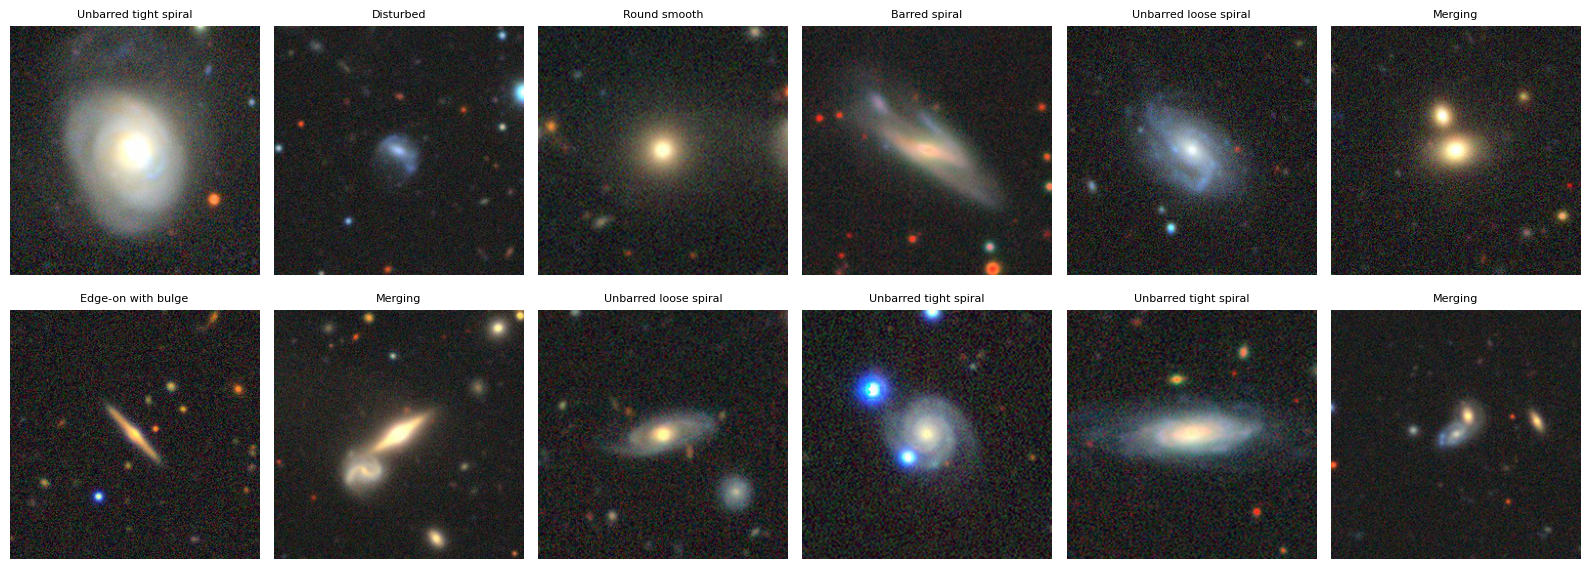

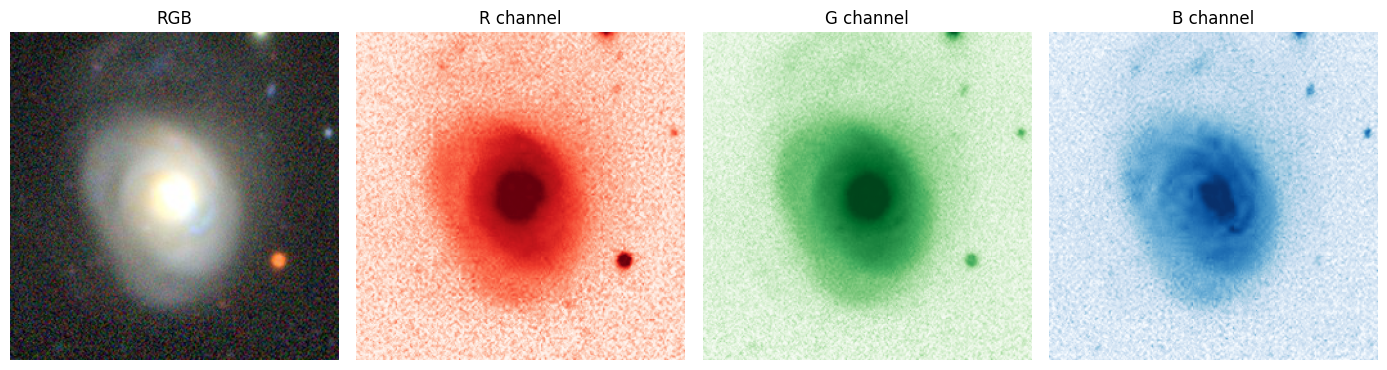

In [12]:
def lab(i):
    if not LABEL_KEY: return ""
    l = int(dataset[i][LABEL_KEY]); return CLASS_NAMES[l] if l < len(CLASS_NAMES) else str(l)

# grid of random galaxies
rng = np.random.default_rng(0)
idx = rng.choice(len(dataset), 12, replace=False)
fig, axs = plt.subplots(2, 6, figsize=(16, 6))
for ax, i in zip(axs.ravel(), idx):
    ax.imshow(get_image(dataset[int(i)])); ax.set_title(lab(int(i)), fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

# per-channel view of one galaxy
arr = np.asarray(get_image(dataset[int(idx[0])]))
fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
axs[0].imshow(arr); axs[0].set_title("RGB")
for j, (n, cm) in enumerate(zip("RGB", ["Reds", "Greens", "Blues"]), 1):
    axs[j].imshow(arr[..., j - 1], cmap=cm); axs[j].set_title(f"{n} channel")
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Load pretrained DINOv2

In [13]:
from transformers import AutoModel

MODEL_NAME = "facebook/dinov2-base"   # try dinov2-small / -large
model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE).eval()
PATCH = model.config.patch_size
print(f"{MODEL_NAME} | patch size {PATCH} | hidden dim {model.config.hidden_size} | params {sum(p.numel() for p in model.parameters())/1e6:.1f}M")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

facebook/dinov2-base | patch size 14 | hidden dim 768 | params 86.6M


## 6. Preprocess image

In [14]:
SIZE = 224                                   # multiple of 14 -> 16x16 patch grid
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def preprocess(pil_images, size=SIZE):
    if isinstance(pil_images, Image.Image): pil_images = [pil_images]
    arr = np.stack([np.asarray(im.resize((size, size), Image.BICUBIC), dtype=np.float32) / 255.0 for im in pil_images])
    x = torch.from_numpy(arr).permute(0, 3, 1, 2)
    return ((x - MEAN) / STD).to(DEVICE)

sample_idx = int(idx[0])
sample_img = get_image(dataset[sample_idx])
x = preprocess(sample_img)
print("input tensor:", tuple(x.shape), "| mean/std:", x.mean().item(), x.std().item())

input tensor: (1, 3, 224, 224) | mean/std: -0.6613081693649292 0.9303779006004333


## 7. Run inference

In [15]:
with torch.no_grad():
    out = model(pixel_values=x)
tokens = out.last_hidden_state
print("last_hidden_state:", tuple(tokens.shape))   # (1, 1 + N_patches, D)

last_hidden_state: (1, 257, 768)


## 8. Extract CLS token

In [16]:
cls_token = tokens[:, 0]
print("CLS token:", tuple(cls_token.shape), "| L2 norm:", cls_token.norm().item())

CLS token: (1, 768) | L2 norm: 49.123592376708984


## 9. Extract patch tokens

In [17]:
patch_tokens = tokens[:, 1:]
h = w = SIZE // PATCH
patch_grid = patch_tokens.reshape(1, h, w, -1)
print("patch tokens:", tuple(patch_tokens.shape), "-> grid:", tuple(patch_grid.shape))

patch tokens: (1, 256, 768) -> grid: (1, 16, 16, 768)


## 10. Inspect tensor dimensions

In [18]:
B, N1, D = tokens.shape
print(f"batch={B} | tokens={N1} (1 CLS + {N1-1} patches) | embedding dim={D}")
print(f"{SIZE}x{SIZE} image / {PATCH}px patches = {h}x{w} grid = {h*w} patches")
assert N1 - 1 == h * w

batch=1 | tokens=257 (1 CLS + 256 patches) | embedding dim=768
224x224 image / 14px patches = 16x16 grid = 256 patches


## 11. Visualize patch grid

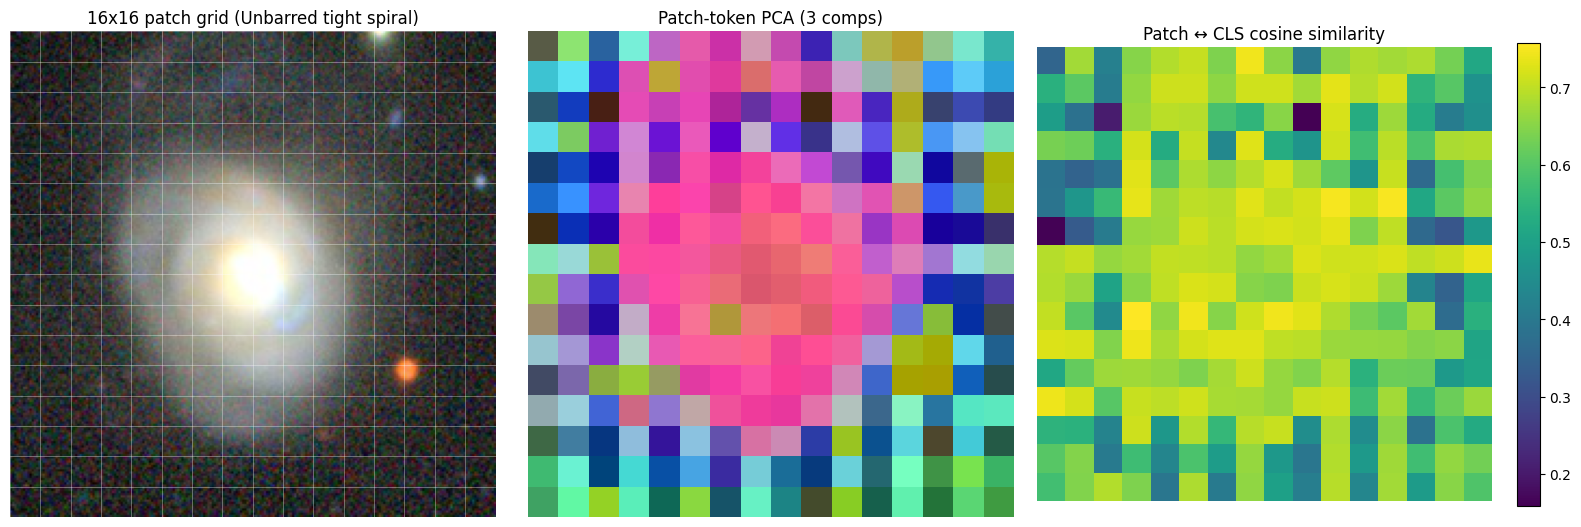

In [19]:
from sklearn.decomposition import PCA

fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))

# (a) image + patch grid
axs[0].imshow(sample_img.resize((SIZE, SIZE)))
for k in range(h + 1):
    axs[0].axhline(k * PATCH - 0.5, color="w", lw=0.4, alpha=0.6)
    axs[0].axvline(k * PATCH - 0.5, color="w", lw=0.4, alpha=0.6)
axs[0].set_title(f"{h}x{w} patch grid ({lab(sample_idx)})"); axs[0].axis("off")

# (b) PCA of patch tokens -> RGB
feats = patch_tokens[0].cpu().numpy()
comp = PCA(n_components=3).fit_transform(feats)
comp = (comp - comp.min(0)) / (comp.max(0) - comp.min(0) + 1e-8)
axs[1].imshow(comp.reshape(h, w, 3), interpolation="nearest"); axs[1].set_title("Patch-token PCA (3 comps)"); axs[1].axis("off")

# (c) cosine similarity of patches to CLS
sim = torch.nn.functional.cosine_similarity(patch_tokens, cls_token[:, None], dim=-1)[0].cpu().numpy()
im = axs[2].imshow(sim.reshape(h, w), cmap="viridis", interpolation="nearest")
axs[2].set_title("Patch ↔ CLS cosine similarity"); axs[2].axis("off"); plt.colorbar(im, ax=axs[2], fraction=0.046)
plt.tight_layout(); plt.show()

## 12. Initial embedding exploration

In [20]:
N_EMB, BATCH = 1000, 32
sel = np.random.default_rng(1).choice(len(dataset), min(N_EMB, len(dataset)), replace=False)

@torch.no_grad()
def embed_batch(indices):
    imgs = [get_image(dataset[int(i)]) for i in indices]
    t = model(pixel_values=preprocess(imgs)).last_hidden_state
    return t[:, 0].cpu().numpy(), t[:, 1:].mean(1).cpu().numpy()

cls_list, mean_list = [], []
for s in tqdm(range(0, len(sel), BATCH)):
    c, m = embed_batch(sel[s:s + BATCH]); cls_list.append(c); mean_list.append(m)
cls_embs, mean_embs = np.concatenate(cls_list), np.concatenate(mean_list)
y = np.array([int(dataset[int(i)][LABEL_KEY]) for i in sel]) if LABEL_KEY else None
print("CLS embeddings:", cls_embs.shape, "| mean-patch embeddings:", mean_embs.shape)

  0%|          | 0/32 [00:00<?, ?it/s]

CLS embeddings: (1000, 768) | mean-patch embeddings: (1000, 768)


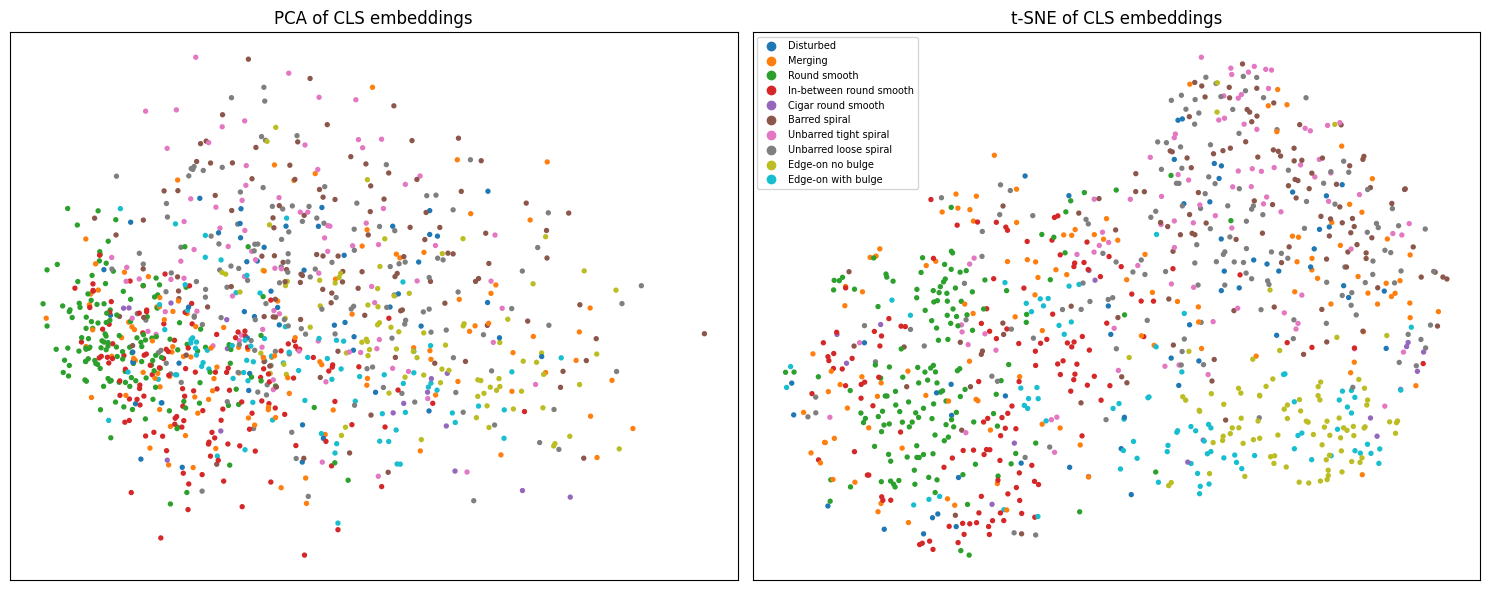

In [21]:
# 2D PCA and t-SNE of CLS embeddings, coloured by class
from sklearn.manifold import TSNE

proj = {"PCA": PCA(n_components=2).fit_transform(cls_embs),
        "t-SNE": TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(cls_embs)}
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, xy) in zip(axs, proj.items()):
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=y if y is not None else "C0", cmap="tab10", s=8)
    ax.set_title(f"{name} of CLS embeddings"); ax.set_xticks([]); ax.set_yticks([])
if y is not None:
    handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=CLASS_NAMES[i]) for i in np.unique(y) if i < len(CLASS_NAMES)]
    axs[1].legend(handles=handles, fontsize=7, loc="best")
plt.tight_layout(); plt.show()

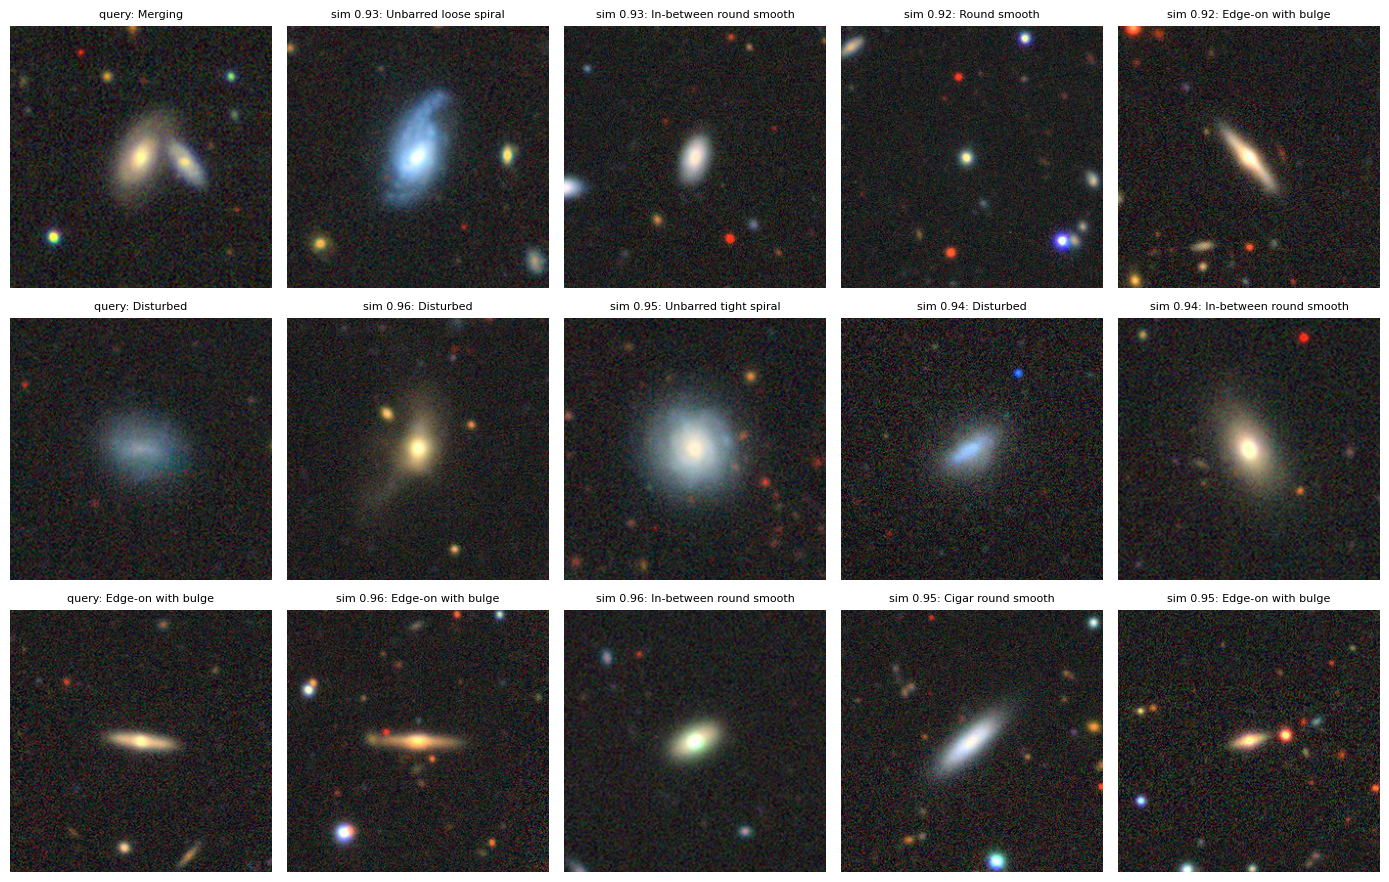

In [22]:
# Nearest-neighbour retrieval (cosine similarity)
E = cls_embs / np.linalg.norm(cls_embs, axis=1, keepdims=True)
S = E @ E.T
fig, axs = plt.subplots(3, 5, figsize=(14, 9))
for r, q in enumerate([0, 1, 2]):
    nn = np.argsort(-S[q])[:5]          # first is the query itself
    for c, j in enumerate(nn):
        axs[r, c].imshow(get_image(dataset[int(sel[j])]))
        axs[r, c].set_title(("query: " if c == 0 else f"sim {S[q, j]:.2f}: ") + (CLASS_NAMES[y[j]] if y is not None else ""), fontsize=8)
        axs[r, c].axis("off")
plt.tight_layout(); plt.show()

In [23]:
# Quick linear probe: how linearly separable are galaxy classes in frozen DINOv2 space?
if y is not None:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    for name, X in [("CLS", cls_embs), ("mean-patch", mean_embs), ("CLS+mean-patch", np.hstack([cls_embs, mean_embs]))]:
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
        sc = StandardScaler().fit(Xtr)
        clf = LogisticRegression(max_iter=2000).fit(sc.transform(Xtr), ytr)
        print(f"{name:15s} linear-probe accuracy: {clf.score(sc.transform(Xte), yte):.3f}")

CLS             linear-probe accuracy: 0.600
mean-patch      linear-probe accuracy: 0.580
CLS+mean-patch  linear-probe accuracy: 0.600
